# CreditParity – Step 6
**BUS/FIN 241A · Final Team Project · Profitable, Fair Lending Decisions**

**Step 6:** Fairness – group metrics, proxies and bias mitigation

**Outcome.** Based on this analysis, CreditParity uses model **(d)** as its final model: reweighing, with `Age` as an input but without `Sex` and `ForeignWorker`. Model (a) is kept as the comparison model; model (c) was tested as an alternative (section 6.4). Step 5 sets the thresholds.

## Step 6 · Fairness

**Question.** Does CreditParity treat applicants differently by **sex**, **age** or **foreign worker status**, and can we fix it?

**Four model variants.** All are logistic regressions with the same preprocessing; only the inputs or the training weights differ.
- **(a) All features** – the model from Steps 4 and 5.
- **(b) Without sensitive features** – `Sex`, `Age` and `ForeignWorker` are removed ("fairness through unawareness").
- **(c) Bias mitigation by reweighing** – all features, but the training applications are reweighted so that, in the weighted training data, default is statistically independent of the combination of age group, sex and foreign worker status (Kamiran & Calders, 2012). The model stays an ordinary logistic regression, so it still gives probabilities and can be explained with SHAP.
- **(d) Reweighing without sex and foreign worker status – final model** – the same reweighing as (c), but `Sex` and `ForeignWorker` are not model inputs. `Age` stays as an input, as a correction for its proxies. This rules out direct sex-based treatment: two applicants who differ only in sex get the same score.

**Decision rule.** Each variant declines an application if its default probability is at or above *its own* cost-optimal threshold (5:1 cost matrix, chosen on out-of-fold predictions as in Step 5). For the zones, this threshold is the lower boundary; the upper boundary follows the precision rule from Step 5: the lowest threshold at which at least 80% of the applications in the red zone are actual defaults.

**Metrics per group.**
- **Rejection rate** – share of applications declined (yellow + red zone, i.e. PD ≥ threshold).
- **Recall** – share of the group's defaults that are caught.
- **False positive rate (FPR)** – share of the group's *good* customers that are declined.
- **Demographic Parity Difference (DPD)** – largest gap in rejection rates between groups. 0 = all groups are declined equally often.
- **Equal Opportunity Difference (EOD)** – largest gap between groups in the FPR, i.e. in the chance that a *creditworthy* applicant is declined. In lending, equal opportunity means that good customers get the same chance of approval regardless of their group. (We also report the recall gap.)

**Data.** Variants are compared on the **out-of-fold predictions of the 4,000 training applications** (larger groups, no test-set use for decisions). The **test set** is used once at the end to confirm the results. Age groups follow Step 2: 19–25, 26–35, 36–50, 51+.

In [1]:
# Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from fairlearn.metrics import (MetricFrame, selection_rate, false_positive_rate,
                               true_positive_rate, count)
from fairlearn.preprocessing import CorrelationRemover   # pip install fairlearn (also in Colab)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)
ZONE_COLORS = {"Green": "#55A868", "Yellow": "#DDAA33", "Red": "#C44E52"}
VARIANT_COLORS = ["#4C72B0", "#8C8C8C", "#937860", "#55A868"]

COST_FN, COST_FP = 5, 1
TARGET_PRECISION = 0.80            # precision rule for the red zone (Step 5)
SENSITIVE = ["Sex", "Age", "ForeignWorker"]
AGE_BINS, AGE_LABELS = [18, 25, 35, 50, 100], ["19-25", "26-35", "36-50", "51+"]

In [2]:
# Load data
# In the repo the file lives in data/. In Google Colab, upload the CSV via the
# folder icon on the left and set DATA_PATH = "german_credit_data_biased_training.csv"
DATA_PATH = "../data/german_credit_data_biased_training.csv"
df = pd.read_csv(DATA_PATH)
df["y"] = (df["Risk"] == "Risk").astype(int)

X = df.drop(columns=["Risk", "y"])
y = df["y"]
categorical = X.select_dtypes(include=["object", "string"]).columns.tolist()
numeric = X.select_dtypes(include="number").columns.tolist()

# Same stratified 80/20 split as in Steps 3 to 5
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

def age_group(data):
    return pd.cut(data["Age"], AGE_BINS, labels=AGE_LABELS).astype(str)

def groups_of(data):
    """The three sensitive attributes used for the fairness analysis."""
    return {"Sex": data["Sex"], "Age group": age_group(data), "ForeignWorker": data["ForeignWorker"]}

for name, g in groups_of(X_train).items():
    print(name, g.value_counts().sort_index().to_dict())

Sex {'female': 1518, 'male': 2482}
Age group {'19-25': 771, '26-35': 1191, '36-50': 1656, '51+': 382}
ForeignWorker {'no': 100, 'yes': 3900}


### Model variants

Reweighing gives each combination of (group, outcome) the weight *expected share / observed share*. Groups in which defaults are over-represented get lower weights for their defaults and higher weights for their good customers, so the model can no longer learn the group's higher default rate from the data. The weights are computed on the training part of each fold only.

In [3]:
def make_model(features):
    cat = [c for c in categorical if c in features]
    num = [c for c in numeric if c in features]
    return Pipeline([
        ("prep", ColumnTransformer([
            ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
            ("num", StandardScaler(), num)])),
        ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ])

def reweighing_weights(data, y_true, keys=("Age group", "Sex", "ForeignWorker")):
    """Kamiran & Calders reweighing: weight = P(group) * P(y) / P(group, y)."""
    g = groups_of(data)
    group = pd.Series(["|".join(t) for t in zip(*[g[k].astype(str) for k in keys])],
                      index=data.index)
    w = pd.Series(1.0, index=data.index)
    for gv in group.unique():
        for label in [0, 1]:
            m = (group == gv) & (y_true == label)
            if m.any():
                w[m] = (group == gv).mean() * (y_true == label).mean() / m.mean()
    return w.to_numpy()

ALL_FEATURES = X.columns.tolist()
NON_SENSITIVE = [c for c in ALL_FEATURES if c not in SENSITIVE]
NO_SEX_FW = [c for c in ALL_FEATURES if c not in ["Sex", "ForeignWorker"]]

VARIANTS = {
    "(a) All features":              {"features": ALL_FEATURES,  "reweigh": False},
    "(b) Without sensitive features": {"features": NON_SENSITIVE, "reweigh": False},
    "(c) Reweighing":                {"features": ALL_FEATURES,  "reweigh": True},
    "(d) Reweighing, no Sex/FW – final": {"features": NO_SEX_FW,  "reweigh": True},
}

def fit_variant(spec, data, y_true, keys=("Age group", "Sex", "ForeignWorker")):
    model = make_model(spec["features"])
    if spec["reweigh"]:
        model.fit(data, y_true, model__sample_weight=reweighing_weights(data, y_true, keys))
    else:
        model.fit(data, y_true)
    return model

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def oof_predictions(spec, **kw):
    """Out-of-fold default probabilities on the training set."""
    p = np.zeros(len(y_train))
    for tr, va in cv.split(X_train, y_train):
        m = fit_variant(spec, X_train.iloc[tr], y_train.iloc[tr], **kw)
        p[va] = m.predict_proba(X_train.iloc[va])[:, 1]
    return p

THRESHOLDS = np.round(np.arange(0.01, 1.00, 0.01), 2)

def cost(p, y_true, t):
    return COST_FN * ((p < t) & (y_true == 1)).sum() + COST_FP * ((p >= t) & (y_true == 0)).sum()

def cost_optimal_threshold(p, y_true):
    return float(THRESHOLDS[int(np.argmin([cost(p, y_true, t) for t in THRESHOLDS]))])

y_tr = y_train.to_numpy()
oof, thresholds = {}, {}
for name, spec in VARIANTS.items():
    oof[name] = oof_predictions(spec)
    thresholds[name] = cost_optimal_threshold(oof[name], y_tr)
    print(f"{name:32s} cost-optimal threshold {thresholds[name]:.2f} | "
          f"out-of-fold ROC AUC {roc_auc_score(y_tr, oof[name]):.3f}")

def upper_for_precision(p, y_true, lower, target=TARGET_PRECISION):
    """Lowest threshold >= lower at which the red zone (p >= threshold) has precision >= target."""
    for t in THRESHOLDS[THRESHOLDS >= lower]:
        red = p >= t
        if red.any() and y_true[red].mean() >= target:
            return float(t)
    return 1.0

uppers = {name: upper_for_precision(oof[name], y_tr, thresholds[name]) for name in VARIANTS}
for name in VARIANTS:
    print(f"{name:32s} zones: green < {thresholds[name]:.2f} ≤ yellow < {uppers[name]:.2f} ≤ red")

(a) All features                 cost-optimal threshold 0.11 | out-of-fold ROC AUC 0.856


(b) Without sensitive features   cost-optimal threshold 0.13 | out-of-fold ROC AUC 0.852


(c) Reweighing                   cost-optimal threshold 0.16 | out-of-fold ROC AUC 0.807


(d) Reweighing, no Sex/FW – final cost-optimal threshold 0.15 | out-of-fold ROC AUC 0.800
(a) All features                 zones: green < 0.11 ≤ yellow < 0.58 ≤ red
(b) Without sensitive features   zones: green < 0.13 ≤ yellow < 0.60 ≤ red
(c) Reweighing                   zones: green < 0.16 ≤ yellow < 0.65 ≤ red
(d) Reweighing, no Sex/FW – final zones: green < 0.15 ≤ yellow < 0.71 ≤ red


### 6.1 Group metrics for each variant (out-of-fold, training set)

In [4]:
def group_report(p, y_true, t, data):
    """Per-group metrics and DPD/EOD for one variant."""
    decline = (p >= t).astype(int)
    by_group, summary = {}, {}
    for attr, g in groups_of(data).items():
        mf = MetricFrame(
            metrics={"Applications": count, "Default rate": lambda yt, yp: yt.mean(),
                     "Rejection rate": selection_rate, "Recall": true_positive_rate,
                     "FPR": false_positive_rate},
            y_true=y_true, y_pred=decline, sensitive_features=g.to_numpy())
        by_group[attr] = mf.by_group
        diff = mf.difference()
        summary[attr] = {"DPD": diff["Rejection rate"], "EOD (FPR gap)": diff["FPR"],
                         "Recall gap": diff["Recall"]}
    return by_group, pd.DataFrame(summary).T

reports = {name: group_report(oof[name], y_tr, thresholds[name], X_train) for name in VARIANTS}

for attr in ["Sex", "Age group", "ForeignWorker"]:
    table = pd.concat({name: reports[name][0][attr][["Applications", "Default rate", "Rejection rate",
                                                     "Recall", "FPR"]]
                       for name in VARIANTS}, names=["Variant", attr])
    print(f"\n=== {attr} ===")
    display(table.round(3))


=== Sex ===


Applications  Default rate  \
Variant                           Sex                                  
(a) All features                  female        1518.0         0.298   
                                  male          2482.0         0.356   
(b) Without sensitive features    female        1518.0         0.298   
                                  male          2482.0         0.356   
(c) Reweighing                    female        1518.0         0.298   
                                  male          2482.0         0.356   
(d) Reweighing, no Sex/FW – final female        1518.0         0.298   
                                  male          2482.0         0.356   

                                          Rejection rate  Recall    FPR  
Variant                           Sex                                    
(a) All features                  female           0.603   0.960  0.452  
                                  male             0.724   0.948  0.601  
(b) Without sensitive features    female           0.491   0.914  0.311  
                                  male             0.741   0.957  0.622  
(c) Reweighing                    female           0.638   0.918  0.518  
                                  male             0.681   0.901  0.560  
(d) Reweighing, no Sex/FW – final female           0.579   0.879  0.452  
                                  male             0.759   0.937  0.661


=== Age group ===


Applications  Default rate  \
Variant                           Age group                               
(a) All features                  19-25             771.0         0.074   
                                  26-35            1191.0         0.207   
                                  36-50            1656.0         0.443   
                                  51+               382.0         0.783   
(b) Without sensitive features    19-25             771.0         0.074   
                                  26-35            1191.0         0.207   
                                  36-50            1656.0         0.443   
                                  51+               382.0         0.783   
(c) Reweighing                    19-25             771.0         0.074   
                                  26-35            1191.0         0.207   
                                  36-50            1656.0         0.443   
                                  51+               382.0         0.783   
(d) Reweighing, no Sex/FW – final 19-25             771.0         0.074   
                                  26-35            1191.0         0.207   
                                  36-50            1656.0         0.443   
                                  51+               382.0         0.783   

                                             Rejection rate  Recall    FPR  
Variant                           Age group                                 
(a) All features                  19-25               0.204   0.667  0.167  
                                  26-35               0.592   0.894  0.513  
                                  36-50               0.890   0.975  0.822  
                                  51+                 0.990   0.997  0.964  
(b) Without sensitive features    19-25               0.169   0.649  0.130  
                                  26-35               0.537   0.866  0.452  
                                  36-50               0.869   0.970  0.789  
                                  51+                 0.984   0.993  0.952  
(c) Reweighing                    19-25               0.447   0.947  0.408  
                                  26-35               0.624   0.894  0.553  
                                  36-50               0.746   0.896  0.627  
                                  51+                 0.877   0.936  0.663  
(d) Reweighing, no Sex/FW – final 19-25               0.466   0.982  0.424  
                                  26-35               0.641   0.898  0.575  
                                  36-50               0.790   0.921  0.687  
                                  51+                 0.866   0.910  0.711


=== ForeignWorker ===


Applications  Default rate  \
Variant                           ForeignWorker                               
(a) All features                  no                    100.0         0.540   
                                  yes                  3900.0         0.329   
(b) Without sensitive features    no                    100.0         0.540   
                                  yes                  3900.0         0.329   
(c) Reweighing                    no                    100.0         0.540   
                                  yes                  3900.0         0.329   
(d) Reweighing, no Sex/FW – final no                    100.0         0.540   
                                  yes                  3900.0         0.329   

                                                 Rejection rate  Recall    FPR  
Variant                           ForeignWorker                                 
(a) All features                  no                      0.980   1.000  0.957  
                                  yes                     0.671   0.950  0.534  
(b) Without sensitive features    no                      0.920   0.963  0.870  
                                  yes                     0.639   0.941  0.491  
(c) Reweighing                    no                      0.820   0.870  0.761  
                                  yes                     0.661   0.909  0.539  
(d) Reweighing, no Sex/FW – final no                      0.880   0.907  0.848  
                                  yes                     0.686   0.917  0.573

In [5]:
# Summary: fairness gaps, cost and ROC AUC per variant
rows = []
for name in VARIANTS:
    s = reports[name][1]
    rows.append({"Variant": name, "Threshold": thresholds[name],
                 "Cost": cost(oof[name], y_tr, thresholds[name]),
                 "ROC AUC": roc_auc_score(y_tr, oof[name]),
                 "Recall": ((oof[name] >= thresholds[name]) & (y_tr == 1)).sum() / y_tr.sum(),
                 **{f"DPD {a}": s.loc[a, "DPD"] for a in s.index},
                 **{f"EOD {a}": s.loc[a, "EOD (FPR gap)"] for a in s.index}})
summary_oof = pd.DataFrame(rows).set_index("Variant")
summary_oof.round(3).T

Variant,(a) All features,(b) Without sensitive features,(c) Reweighing,"(d) Reweighing, no Sex/FW – final"
Threshold,0.110,0.130,0.160,0.150
Cost,1762.000,1711.000,2067.000,2093.000
ROC AUC,0.856,0.852,0.807,0.800
Recall,0.952,0.942,0.907,0.917
DPD Sex,0.121,0.251,0.044,0.180
DPD Age group,0.786,0.816,0.429,0.401
DPD ForeignWorker,0.309,0.281,0.159,0.194
EOD Sex,0.149,0.311,0.041,0.209
EOD Age group,0.797,0.822,0.255,0.286
EOD ForeignWorker,0.423,0.378,0.222,0.275


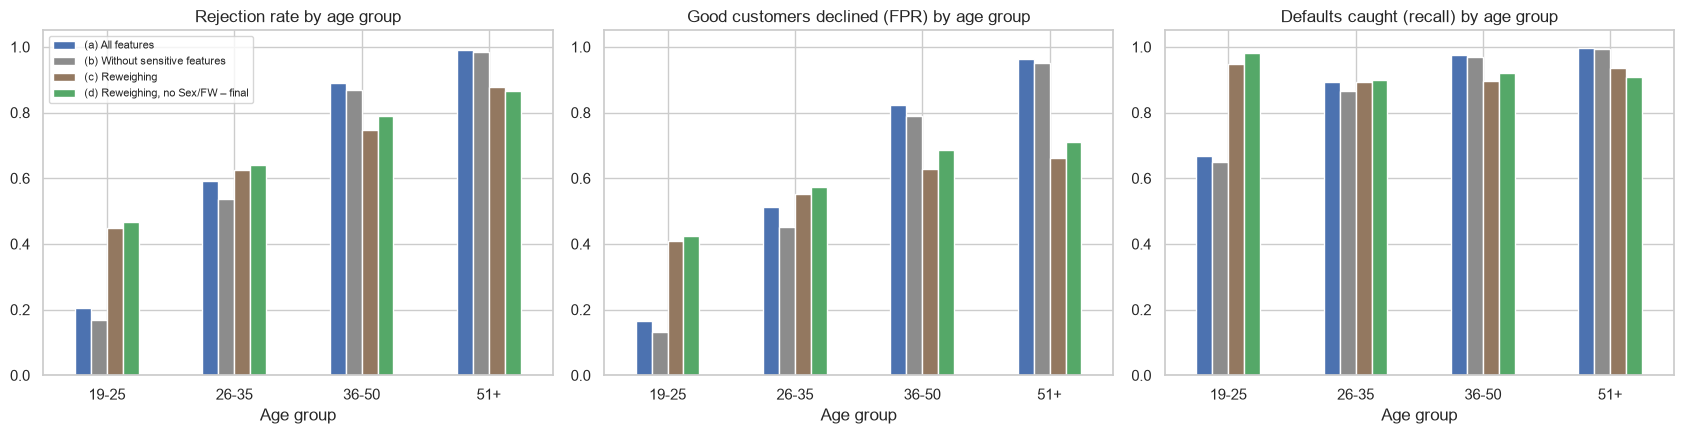

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (metric, title) in zip(axes, [("Rejection rate", "Rejection rate"),
                                      ("FPR", "Good customers declined (FPR)"),
                                      ("Recall", "Defaults caught (recall)")]):
    data = pd.DataFrame({name: reports[name][0]["Age group"][metric] for name in VARIANTS})
    data.plot.bar(ax=ax, color=VARIANT_COLORS, rot=0, legend=(metric == "Rejection rate"))
    ax.set_title(f"{title} by age group")
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("Age group")
axes[0].legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

**Result 6.1 – group metrics (out-of-fold, 4,000 training applications).**

| | (a) All features | (b) Without sensitive features | (c) Reweighing | **(d) Reweighing, no Sex/FW – final** |
|---|---|---|---|---|
| Threshold | 0.11 | 0.13 | 0.16 | **0.15** |
| Cost | 1,762 | 1,711 | 2,067 | **2,093** |
| ROC AUC | 0.856 | 0.852 | 0.807 | **0.800** |
| Recall | 0.952 | 0.942 | 0.907 | **0.917** |
| DPD / EOD – Age group | 0.79 / 0.80 | 0.82 / 0.82 | 0.43 / 0.26 | **0.40 / 0.29** |
| DPD / EOD – Sex | 0.12 / 0.15 | 0.25 / 0.31 | 0.04 / 0.04 | **0.18 / 0.21** |
| DPD / EOD – ForeignWorker | 0.31 / 0.42 | 0.28 / 0.38 | 0.16 / 0.22 | **0.19 / 0.28** |

- **Age is by far the largest gap.** With all features, 20% of applicants aged 19–25 are declined, but 99% of those aged 51+. More importantly for fairness, **96% of the *good* customers aged 51+ are declined, compared with 17% of good customers aged 19–25** (EOD 0.80). Part of the rejection gap reflects real differences in the data (default rate 7% vs. 78%), which is why demographic parity alone is not the right target for age. The FPR gap, however, shows that creditworthy older applicants have almost no chance of approval.
- **Sex.** With all features, men are declined more often than women (72% vs. 60%), in line with their higher default rate (36% vs. 30%). Good male customers are also declined more often (FPR 0.60 vs. 0.45).
- **ForeignWorker.** The small group of applicants who are *not* foreign workers (100 in the training set, default rate 54%) is declined in 98% of cases by model (a).
- **(b) Dropping the sensitive features does not reduce the gaps.** The age gap stays the same (EOD 0.82), and the sex gap even doubles (EOD 0.31). Cost and ROC AUC are almost unchanged.
- **(c) and (d) – reweighing reduces the age gap by about two thirds** (EOD 0.80 → 0.26 / 0.29). The price is a weaker model (ROC AUC 0.856 → about 0.80) and about 17–19% higher cost.
- **Sex: (c) and (d) differ.** (c) almost removes the sex gap (0.04), but only because it uses `Sex` as an input (section 6.4). The final model (d) does not; its sex gap is 0.21 and works against men (good customers declined: women 45%, men 66%).
- **Leveling down.** Reweighing narrows the age gap from both sides: good customers aged 51+ are declined less often (0.96 → 0.71 with (d)), but good customers aged 19–25 are declined *more* often (0.17 → 0.42). A fairer model is not automatically better for every group.

### 6.2 Why dropping sensitive features is not enough: proxies

If the remaining 17 features can predict a sensitive attribute, the model can still treat the groups differently without ever seeing the attribute. We test this by predicting each sensitive attribute from the non-sensitive features only (5-fold CV, logistic regression). A ROC AUC of 0.5 means "no information", 1.0 means "perfect proxy".

In [7]:
proxy_targets = {
    "Age 51+": (X_train["Age"] > 50).astype(int),
    "Age 36+": (X_train["Age"] > 35).astype(int),
    "Female": (X_train["Sex"] == "female").astype(int),
    "Not a foreign worker": (X_train["ForeignWorker"] == "no").astype(int),
}
proxy_rows = []
for target, t_y in proxy_targets.items():
    auc = cross_val_score(make_model(NON_SENSITIVE), X_train[NON_SENSITIVE], t_y,
                          cv=cv, scoring="roc_auc")
    proxy_rows.append({"Sensitive attribute": target, "ROC AUC from other features": auc.mean(),
                       "Std": auc.std()})
pd.DataFrame(proxy_rows).set_index("Sensitive attribute").round(3)

,ROC AUC from other features,Std
Sensitive attribute,,
Age 51+,0.904,0.012
Age 36+,0.883,0.008
Female,0.692,0.017
Not a foreign worker,0.646,0.015


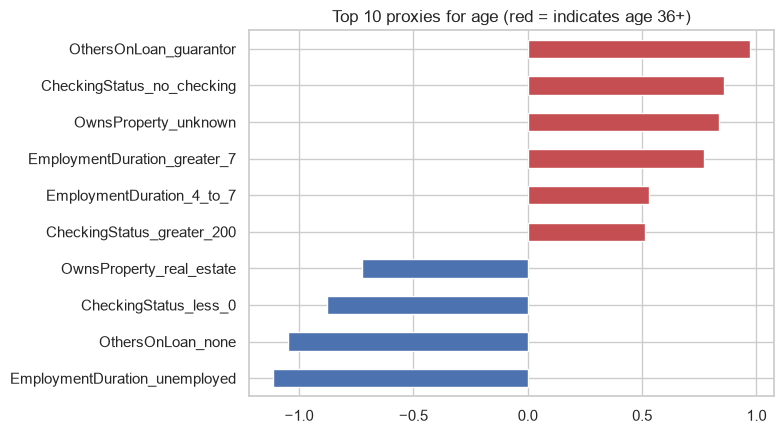

In [8]:
# Which features carry the age information? Strongest predictors of "Age 36+"
proxy_model = make_model(NON_SENSITIVE).fit(X_train[NON_SENSITIVE], proxy_targets["Age 36+"])
names = [n.split("__", 1)[1] for n in proxy_model.named_steps["prep"].get_feature_names_out()]
coef = pd.Series(proxy_model.named_steps["model"].coef_[0], index=names)
top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(10)
top.sort_values().plot.barh(figsize=(8, 4.5),
    color=["#C44E52" if v > 0 else "#4C72B0" for v in top.sort_values()])
plt.title("Top 10 proxies for age (red = indicates age 36+)")
plt.tight_layout()
plt.show()

In [9]:
# Does mitigation work without the sensitive attributes? And how does another method compare?
extra = {
    "(c) Reweighing (all features)": oof["(c) Reweighing"],
    "Reweighing without sensitive features": oof_predictions(
        {"features": NON_SENSITIVE, "reweigh": True}),
}

def correlation_remover_oof(alpha):
    """fairlearn CorrelationRemover: removes the linear correlation of all features with
    Age, Sex and ForeignWorker (alpha = 1: fully, alpha = 0.5: halfway)."""
    p = np.zeros(len(y_train))
    for tr, va in cv.split(X_train, y_train):
        prep = ColumnTransformer([
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
            ("num", StandardScaler(), numeric)])
        prep.fit(X_train.iloc[tr])
        ids = [i for i, n in enumerate(prep.get_feature_names_out())
               if n == "num__Age" or n.startswith(("cat__Sex_", "cat__ForeignWorker_"))]
        m = Pipeline([("prep", prep),
                      ("cr", CorrelationRemover(sensitive_feature_ids=ids, alpha=alpha)),
                      ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])
        m.fit(X_train.iloc[tr], y_train.iloc[tr])
        p[va] = m.predict_proba(X_train.iloc[va])[:, 1]
    return p

for alpha in [0.5, 1.0]:
    extra[f"CorrelationRemover (alpha = {alpha})"] = correlation_remover_oof(alpha)

rows = []
for name, p in {"(a) All features": oof["(a) All features"], **extra}.items():
    t = cost_optimal_threshold(p, y_tr)
    by_group, s = group_report(p, y_tr, t, X_train)
    fpr_age = by_group["Age group"]["FPR"]
    rows.append({"Method": name, "Threshold": t, "Cost": cost(p, y_tr, t),
                 "ROC AUC": roc_auc_score(y_tr, p),
                 "FPR 19-25": fpr_age["19-25"], "FPR 51+": fpr_age["51+"],
                 "EOD Age group": s.loc["Age group", "EOD (FPR gap)"],
                 "EOD Sex": s.loc["Sex", "EOD (FPR gap)"]})
pd.DataFrame(rows).set_index("Method").round(3)

,Threshold,Cost,ROC AUC,FPR 19-25,FPR 51+,EOD Age group,EOD Sex
Method,,,,,,,
(a) All features,0.11,1762,0.856,0.167,0.964,0.797,0.149
(c) Reweighing (all features),0.16,2067,0.807,0.408,0.663,0.255,0.041
Reweighing without sensitive features,0.17,1911,0.831,0.254,0.964,0.710,0.225
CorrelationRemover (alpha = 0.5),0.13,1838,0.836,0.328,0.831,0.504,0.191
CorrelationRemover (alpha = 1.0),0.11,2565,0.730,0.978,0.711,0.267,0.032


**Result 6.2 – proxies.**
- **Age can be reconstructed from the other features.** Without seeing `Age`, a logistic regression identifies applicants aged 51+ with a ROC AUC of **0.90** (36+: 0.88). The strongest proxies are a guarantor on the loan (`OthersOnLoan`), the checking account status, unknown property and employment duration over 7 years. Sex (0.69) and foreign worker status (0.65) are weaker, but still not hidden.
- **Mitigation needs the sensitive attribute.** Reweighing *without* the sensitive features hardly helps (age EOD 0.71; 96% of good customers aged 51+ are still declined). The model can only offset the proxies if it knows the attribute it should be fair about. This is the opposite of "fairness through unawareness".
- **Another method for comparison.** fairlearn's `CorrelationRemover` removes the correlation between the features and the sensitive attributes. Halfway (alpha = 0.5) it reduces the age EOD to 0.50 at a cost of 1,838. Fully applied (alpha = 1) it overcorrects: ROC AUC falls to 0.73 and 98% of good customers aged 19–25 are declined. We also tried fairlearn's `ExponentiatedGradient`, but it optimizes accuracy rather than our 5:1 cost matrix and produced unusable probabilities on this data, so it is not shown.

**Why (d) still works for age.** Model (d) keeps `Age` as an input, so reweighing can offset the age proxies. It drops only `Sex` and `ForeignWorker`, which the other features reflect only weakly (ROC AUC 0.69 and 0.65).

**Answer to the key question.** Simply dropping sensitive features is **not enough**. The age information is still in the data through proxies, and the age gap stays at the same level.

### 6.3 Fairness per zone

Which groups are approved automatically, sent to an analyst, or declined with an explanation? We show the zone shares per group for each variant (lower boundary = the variant's own cost-optimal threshold, upper boundary = the variant's own 80%-precision boundary).

In [10]:
def zone_of(p, lower, upper):
    return np.where(p < lower, "Green", np.where(p >= upper, "Red", "Yellow"))

zone_rows = []
for name in VARIANTS:
    zone = pd.Series(zone_of(oof[name], thresholds[name], uppers[name]), index=X_train.index)
    for attr, g in groups_of(X_train).items():
        shares = pd.crosstab(g, zone, normalize="index").reindex(columns=["Green", "Yellow", "Red"],
                                                                 fill_value=0)
        for grp, r in shares.iterrows():
            zone_rows.append({"Variant": name, "Attribute": attr, "Group": grp, **r.to_dict()})
zone_shares = pd.DataFrame(zone_rows).set_index(["Variant", "Attribute", "Group"])
zone_shares.round(3)

Green  Yellow    Red
Variant                           Attribute     Group                       
(a) All features                  Sex           female  0.397   0.384  0.219
                                                male    0.276   0.481  0.243
                                  Age group     19-25   0.796   0.198  0.005
                                                26-35   0.408   0.534  0.058
                                                36-50   0.110   0.553  0.337
                                                51+     0.010   0.191  0.798
                                  ForeignWorker no      0.020   0.560  0.420
                                                yes     0.329   0.442  0.229
(b) Without sensitive features    Sex           female  0.509   0.338  0.153
                                                male    0.259   0.487  0.255
                                  Age group     19-25   0.831   0.165  0.004
                                                26-35   0.463   0.478  0.060
                                                36-50   0.131   0.566  0.303
                                                51+     0.016   0.228  0.757
                                  ForeignWorker no      0.080   0.610  0.310
                                                yes     0.361   0.426  0.214
(c) Reweighing                    Sex           female  0.362   0.509  0.128
                                                male    0.319   0.517  0.164
                                  Age group     19-25   0.553   0.402  0.045
                                                26-35   0.376   0.535  0.089
                                                36-50   0.254   0.546  0.200
                                                51+     0.123   0.534  0.343
                                  ForeignWorker no      0.180   0.620  0.200
                                                yes     0.339   0.511  0.149
(d) Reweighing, no Sex/FW – final Sex           female  0.421   0.524  0.055
                                                male    0.241   0.617  0.142
                                  Age group     19-25   0.534   0.431  0.035
                                                26-35   0.359   0.568  0.074
                                                36-50   0.210   0.662  0.128
                                                51+     0.134   0.579  0.288
                                  ForeignWorker no      0.120   0.720  0.160
                                                yes     0.314   0.578  0.108

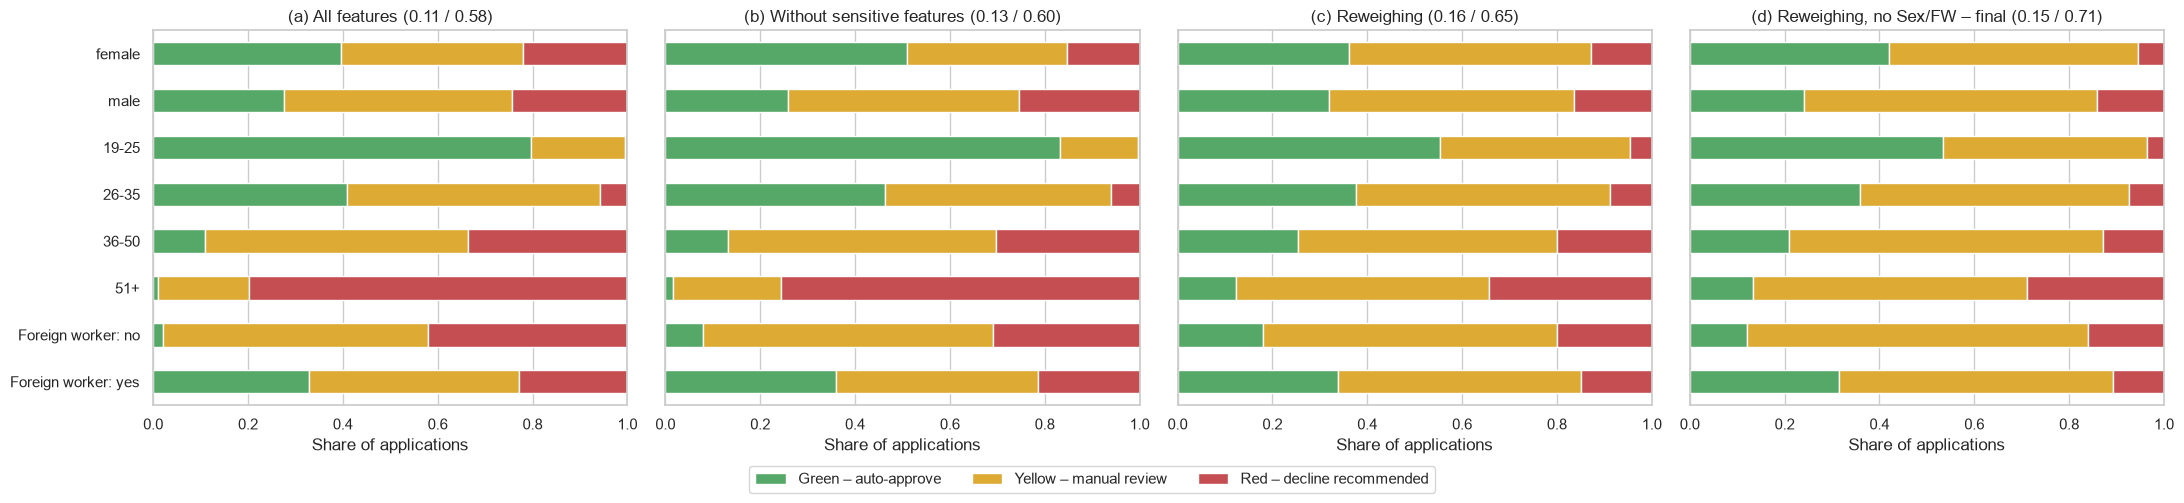

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(22, 4.8), sharey=True)
for ax, name in zip(axes, VARIANTS):
    zs = zone_shares.loc[name]
    zs.index = [f"Foreign worker: {g}" if a == "ForeignWorker" else g for a, g in zs.index]
    zs.plot.barh(stacked=True, ax=ax, color=[ZONE_COLORS[z] for z in zs.columns], legend=False)
    ax.set_title(f"{name} ({thresholds[name]:.2f} / {uppers[name]:.2f})")
    ax.set_xlim(0, 1)
    ax.set_xlabel("Share of applications")
    ax.invert_yaxis()
fig.legend(["Green – auto-approve", "Yellow – manual review", "Red – decline recommended"],
           loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.06))
plt.tight_layout()
plt.show()

In [12]:
# Where do the GOOD customers of each age group end up? (counts, out-of-fold)
def good_customer_zones(p_dict, y_true, data, lowers, upper_dict):
    ag = age_group(data).to_numpy()
    rows = []
    for name in VARIANTS:
        zone = zone_of(p_dict[name], lowers[name], upper_dict[name])
        for grp in AGE_LABELS:
            m = (ag == grp) & (y_true == 0)
            rows.append({"Variant": name, "Age group": grp, "Good customers": int(m.sum()),
                         "Green": int((m & (zone == "Green")).sum()),
                         "Yellow": int((m & (zone == "Yellow")).sum()),
                         "Red": int((m & (zone == "Red")).sum()),
                         "PD ≥ lower boundary (yellow + red)": (m & (zone != "Green")).sum() / m.sum(),
                         "Auto-declined (red)": (m & (zone == "Red")).sum() / m.sum()})
    return pd.DataFrame(rows).set_index(["Variant", "Age group"])

good_zones_oof = good_customer_zones(oof, y_tr, X_train, thresholds, uppers)
good_zones_oof.round(3)

Good customers  Green  Yellow  \
Variant                           Age group                                  
(a) All features                  19-25                 714    595     117   
                                  26-35                 945    460     461   
                                  36-50                 922    164     640   
                                  51+                    83      3      39   
(b) Without sensitive features    19-25                 714    621      92   
                                  26-35                 945    518     402   
                                  36-50                 922    195     622   
                                  51+                    83      4      42   
(c) Reweighing                    19-25                 714    423     268   
                                  26-35                 945    422     470   
                                  36-50                 922    344     539   
                                  51+                    83     28      50   
(d) Reweighing, no Sex/FW – final 19-25                 714    411     285   
                                  26-35                 945    402     505   
                                  36-50                 922    289     610   
                                  51+                    83     24      58   

                                             Red  \
Variant                           Age group        
(a) All features                  19-25        2   
                                  26-35       24   
                                  36-50      118   
                                  51+         41   
(b) Without sensitive features    19-25        1   
                                  26-35       25   
                                  36-50      105   
                                  51+         37   
(c) Reweighing                    19-25       23   
                                  26-35       53   
                                  36-50       39   
                                  51+          5   
(d) Reweighing, no Sex/FW – final 19-25       18   
                                  26-35       38   
                                  36-50       23   
                                  51+          1   

                                             PD ≥ lower boundary (yellow + red)  \
Variant                           Age group                                       
(a) All features                  19-25                                   0.167   
                                  26-35                                   0.513   
                                  36-50                                   0.822   
                                  51+                                     0.964   
(b) Without sensitive features    19-25                                   0.130   
                                  26-35                                   0.452   
                                  36-50                                   0.789   
                                  51+                                     0.952   
(c) Reweighing                    19-25                                   0.408   
                                  26-35                                   0.553   
                                  36-50                                   0.627   
                                  51+                                     0.663   
(d) Reweighing, no Sex/FW – final 19-25                                   0.424   
                                  26-35                                   0.575   
                                  36-50                                   0.687   
                                  51+                                     0.711   

                                             Auto-declined (red)  
Variant                           Age group                       
(a) All features                  19-25                    0.003  
       

**Result 6.3 – fairness per zone (out-of-fold).** Each variant uses its own boundaries: (a) 0.11 / 0.58, (b) 0.13 / 0.60, (c) 0.16 / 0.65, (d) 0.15 / 0.71.

| Zone shares 🟢 / 🟡 / 🔴 | (a) All features | (d) Final model |
|---|---|---|
| Age 19–25 | 79.6% / 19.8% / 0.5% | 53.4% / 43.1% / 3.5% |
| Age 26–35 | 40.8% / 53.4% / 5.8% | 35.9% / 56.8% / 7.4% |
| Age 36–50 | 11.0% / 55.3% / 33.7% | 21.0% / 66.2% / 12.8% |
| Age 51+ | 1.0% / 19.1% / **79.8%** | 13.4% / 57.9% / **28.8%** |
| Female | 39.7% / 38.4% / 21.9% | 42.1% / 52.4% / 5.5% |
| Male | 27.6% / 48.1% / 24.3% | 24.1% / 61.7% / 14.2% |
| Foreign worker: no / yes (red) | 42.0% / 22.9% | 16.0% / 10.8% |

**Good customers aged 51+ (83 in the training set):**

| | 🟢 Green | 🟡 Yellow | 🔴 Red (automatic decline) |
|---|---|---|---|
| (a) All features | 3 | 39 | **41 (49%)** |
| (b) Without sensitive features | 4 | 42 | 37 (45%) |
| (c) Reweighing | 28 | 50 | 5 (6%) |
| **(d) Final model** | 24 | 58 | **1 (1%)** |

- **With model (a), half of the creditworthy applicants aged 51+ are declined automatically**, and 80% of all applicants aged 51+ land in the red zone.
- **With the final model (d), only 1 of 83 good customers aged 51+ is declined automatically.** Most go to manual review (58) or are approved directly (24), so a human looks at their case.
- **Young applicants.** With (d), 42% of good customers aged 19–25 are not auto-approved (vs. 17% with (a)), but only 18 of 714 (2.5%) are declined automatically; the rest go to an analyst.
- **Sex.** With (d), men are auto-approved less often (24% vs. 42%) and land in the red zone more often (14% vs. 6%) than women. Section 6.4 shows why.
- **Implication.** The bank should monitor zone shares by group, not only overall rejection rates. The dashboard (Step 9) will show these shares.

### 6.4 Sex: equal treatment vs. equal outcomes

Model (c) has the smallest sex gap, but it uses `Sex` as an input. Its coefficients show that, *holding all other features equal*, it rates women as riskier than men (Step 7). That is direct sex-based treatment, which CreditParity rules out. Model (d) removes `Sex` as an input. To check whether the result depends on the exact way sex is removed, we add a third approach:

- **(e) Model (c) with a neutral sex effect** – trained exactly like (c), but at prediction time every applicant gets the same, average contribution for `Sex` and `ForeignWorker`. Men and women with the same other features therefore get the same score.

If (d) and (e) show the same sex gap, the gap is not caused by how we remove sex, but by the data itself.

In [13]:
def fit_neutral(data, y_true):
    """Variant (e): model (c) whose Sex and ForeignWorker columns are set to their
    training average at prediction time."""
    m = fit_variant(VARIANTS["(c) Reweighing"], data, y_true)
    Z = m.named_steps["prep"].transform(data)
    m.neutral_values_ = np.asarray(Z.mean(axis=0)).ravel()
    return m

def predict_neutral(m, data):
    Z = m.named_steps["prep"].transform(data)
    Z = Z.toarray() if hasattr(Z, "toarray") else np.array(Z, dtype=float)
    cols = [i for i, n in enumerate(m.named_steps["prep"].get_feature_names_out())
            if n.startswith(("cat__Sex_", "cat__ForeignWorker_"))]
    Z[:, cols] = m.neutral_values_[cols]
    return m.named_steps["model"].predict_proba(Z)[:, 1]

p_e = np.zeros(len(y_tr))
for tr, va in cv.split(X_train, y_train):
    p_e[va] = predict_neutral(fit_neutral(X_train.iloc[tr], y_train.iloc[tr]), X_train.iloc[va])
t_e = cost_optimal_threshold(p_e, y_tr)
u_e = upper_for_precision(p_e, y_tr, t_e)

def sex_summary(p, y_true, data, lower, upper):
    by_group, s = group_report(p, y_true, lower, data)
    zone = pd.Series(zone_of(p, lower, upper), index=data.index)
    shares = pd.crosstab(data["Sex"], zone, normalize="index").reindex(columns=["Green", "Yellow", "Red"], fill_value=0)
    fpr = by_group["Sex"]["FPR"]
    return {"Boundaries": f"{lower:.2f} / {upper:.2f}", "Cost": cost(p, y_true, lower),
            "ROC AUC": round(roc_auc_score(y_true, p), 3),
            "EOD Sex": round(s.loc["Sex", "EOD (FPR gap)"], 3),
            "FPR female / male": f"{fpr['female']:.2f} / {fpr['male']:.2f}",
            "Zones female (G/Y/R)": " / ".join(f"{v:.0%}" for v in shares.loc["female"]),
            "Zones male (G/Y/R)": " / ".join(f"{v:.0%}" for v in shares.loc["male"]),
            "EOD Age group": round(s.loc["Age group", "EOD (FPR gap)"], 3)}

sex_rows = {name: sex_summary(oof[name], y_tr, X_train, thresholds[name], uppers[name])
            for name in ["(a) All features", "(c) Reweighing", "(d) Reweighing, no Sex/FW – final"]}
sex_rows["(e) Model (c), neutral sex effect"] = sex_summary(p_e, y_tr, X_train, t_e, u_e)
print("Out-of-fold (training set)")
pd.DataFrame(sex_rows).T

Out-of-fold (training set)


,Boundaries,Cost,ROC AUC,EOD Sex,FPR female / male,Zones female (G/Y/R),Zones male (G/Y/R),EOD Age group
(a) All features,0.11 / 0.58,1762,0.856,0.149,0.45 / 0.60,40% / 38% / 22%,28% / 48% / 24%,0.797
(c) Reweighing,0.16 / 0.65,2067,0.807,0.041,0.52 / 0.56,36% / 51% / 13%,32% / 52% / 16%,0.255
"(d) Reweighing, no Sex/FW – final",0.15 / 0.71,2093,0.8,0.209,0.45 / 0.66,42% / 52% / 6%,24% / 62% / 14%,0.286
"(e) Model (c), neutral sex effect",0.11 / 0.71,2050,0.806,0.206,0.52 / 0.72,36% / 57% / 6%,19% / 65% / 16%,0.332


In [14]:
# Sex coefficients: only (a) and (c) use Sex as an input
coef_sex = {}
for name in ["(a) All features", "(c) Reweighing"]:
    m = fit_variant(VARIANTS[name], X_train, y_train)
    c = pd.Series(m.named_steps["model"].coef_[0], index=m.named_steps["prep"].get_feature_names_out())
    coef_sex[name] = {"Sex_female": c["cat__Sex_female"], "Sex_male": c["cat__Sex_male"],
                      "female − male (log-odds)": c["cat__Sex_female"] - c["cat__Sex_male"]}
pd.DataFrame(coef_sex).round(3)

,(a) All features,(c) Reweighing
Sex_female,0.213,0.210
Sex_male,-0.488,-0.503
female − male (log-odds),0.701,0.713


**Result 6.4 – equal treatment vs. equal outcomes for sex.**

| Out-of-fold | (a) All features | (c) Reweighing | **(d) Final** | (e) (c) with neutral sex effect |
|---|---|---|---|---|
| Uses sex for the score | yes | yes | **no** | no |
| Cost | 1,762 | 2,067 | **2,093** | 2,050 |
| ROC AUC | 0.856 | 0.807 | **0.800** | 0.806 |
| EOD Sex | 0.15 | **0.04** | 0.21 | 0.21 |
| Good customers declined, female / male | 0.45 / 0.60 | 0.52 / 0.56 | 0.45 / 0.66 | 0.52 / 0.72 |
| EOD Age group | 0.80 | 0.26 | 0.29 | 0.33 |

- **Model (c) achieves equal outcomes through unequal treatment.** Its sex coefficients are female +0.21 and male −0.50: with all other features equal, a woman's log-odds of default are 0.71 higher than a man's. The small sex gap of (c) exists only because this offsets the less favorable other features of men in this dataset.
- **Every model that treats sex equally shows the same gap.** (d) (sex not an input) and (e) (sex in training, but the same sex effect for everyone at prediction time) both end up at an EOD of about **0.21**, against men. The gap therefore does not depend on how sex is removed. It comes from differences in the other features between men and women.
- **The trade-off.** On this data, CreditParity can have *equal treatment* (same score for the same features, regardless of sex) or *equal outcomes* (same decline rates for good men and women), but not both. **CreditParity chooses equal treatment** (model (d)): no applicant's score depends directly on sex. The remaining outcome gap is documented, needs legal review (indirect discrimination) and should be monitored.
- **Age is treated differently on purpose.** Model (d) still uses `Age` directly, as a correction for its strong proxies. Without it, the age gap returns (6.2). This also needs legal review.

### 6.5 Confirmation on the test set

The three variants are trained on all 4,000 training applications and applied with their thresholds to the 1,000 test applications. Group sizes are smaller here (only 23 test applicants are not foreign workers), so the test numbers are less precise.

In [15]:
y_te = y_test.to_numpy()
test_rows, test_reports = [], {}
for name, spec in VARIANTS.items():
    model = fit_variant(spec, X_train, y_train)
    p = model.predict_proba(X_test)[:, 1]
    t = thresholds[name]
    by_group, s = group_report(p, y_te, t, X_test)
    test_reports[name] = by_group
    test_rows.append({"Variant": name, "Threshold": t, "Cost": cost(p, y_te, t),
                      "ROC AUC": roc_auc_score(y_te, p),
                      "Recall": ((p >= t) & (y_te == 1)).sum() / y_te.sum(),
                      "Rejection rate": (p >= t).mean(),
                      **{f"DPD {a}": s.loc[a, "DPD"] for a in s.index},
                      **{f"EOD {a}": s.loc[a, "EOD (FPR gap)"] for a in s.index}})
summary_test = pd.DataFrame(test_rows).set_index("Variant")
display(summary_test.round(3).T)

print("FPR (good customers declined) by age group, test set")
pd.DataFrame({name: test_reports[name]["Age group"]["FPR"] for name in VARIANTS}).rename_axis("Age group").round(3)

Variant,(a) All features,(b) Without sensitive features,(c) Reweighing,"(d) Reweighing, no Sex/FW – final"
Threshold,0.110,0.130,0.160,0.150
Cost,409.000,414.000,488.000,467.000
ROC AUC,0.867,0.864,0.816,0.811
Recall,0.958,0.946,0.925,0.949
Rejection rate,0.659,0.640,0.672,0.699
DPD Sex,0.103,0.200,0.043,0.167
DPD Age group,0.825,0.850,0.421,0.430
DPD ForeignWorker,0.260,0.190,0.247,0.175
EOD Sex,0.109,0.233,0.026,0.174
EOD Age group,0.812,0.833,0.308,0.365


FPR (good customers declined) by age group, test set


,(a) All features,(b) Without sensitive features,(c) Reweighing,"(d) Reweighing, no Sex/FW – final"
Age group,,,,
19-25,0.141,0.119,0.454,0.492
26-35,0.454,0.437,0.489,0.502
36-50,0.818,0.788,0.654,0.684
51+,0.952,0.952,0.762,0.857


In [16]:
# Good customers by age group and zone on the test set
p_test_by_variant = {name: fit_variant(spec, X_train, y_train).predict_proba(X_test)[:, 1]
                     for name, spec in VARIANTS.items()}
good_customer_zones(p_test_by_variant, y_te, X_test, thresholds, uppers).round(3)

Good customers  Green  Yellow  \
Variant                           Age group                                  
(a) All features                  19-25                 185    159      26   
                                  26-35                 229    125     102   
                                  36-50                 231     42     156   
                                  51+                    21      1      12   
(b) Without sensitive features    19-25                 185    163      22   
                                  26-35                 229    129      98   
                                  36-50                 231     49     153   
                                  51+                    21      1      12   
(c) Reweighing                    19-25                 185    101      78   
                                  26-35                 229    117     105   
                                  36-50                 231     80     139   
                                  51+                    21      5      16   
(d) Reweighing, no Sex/FW – final 19-25                 185     94      87   
                                  26-35                 229    114     112   
                                  36-50                 231     73     151   
                                  51+                    21      3      18   

                                             Red  \
Variant                           Age group        
(a) All features                  19-25        0   
                                  26-35        2   
                                  36-50       33   
                                  51+          8   
(b) Without sensitive features    19-25        0   
                                  26-35        2   
                                  36-50       29   
                                  51+          8   
(c) Reweighing                    19-25        6   
                                  26-35        7   
                                  36-50       12   
                                  51+          0   
(d) Reweighing, no Sex/FW – final 19-25        4   
                                  26-35        3   
                                  36-50        7   
                                  51+          0   

                                             PD ≥ lower boundary (yellow + red)  \
Variant                           Age group                                       
(a) All features                  19-25                                   0.141   
                                  26-35                                   0.454   
                                  36-50                                   0.818   
                                  51+                                     0.952   
(b) Without sensitive features    19-25                                   0.119   
                                  26-35                                   0.437   
                                  36-50                                   0.788   
                                  51+                                     0.952   
(c) Reweighing                    19-25                                   0.454   
                                  26-35                                   0.489   
                                  36-50                                   0.654   
                                  51+                                     0.762   
(d) Reweighing, no Sex/FW – final 19-25                                   0.492   
                                  26-35                                   0.502   
                                  36-50                                   0.684   
                                  51+                                     0.857   

                                             Auto-declined (red)  
Variant                           Age group                       
(a) All features                  19-25                    0.000  
       

In [17]:
# Sex comparison on the test set, incl. variant (e)
m_e = fit_neutral(X_train, y_train)
sex_test = {name: sex_summary(p_test_by_variant[name], y_te, X_test, thresholds[name], uppers[name])
            for name in ["(a) All features", "(c) Reweighing", "(d) Reweighing, no Sex/FW – final"]}
sex_test["(e) Model (c), neutral sex effect"] = sex_summary(predict_neutral(m_e, X_test), y_te, X_test, t_e, u_e)
pd.DataFrame(sex_test).T

,Boundaries,Cost,ROC AUC,EOD Sex,FPR female / male,Zones female (G/Y/R),Zones male (G/Y/R),EOD Age group
(a) All features,0.11 / 0.58,409,0.867,0.109,0.44 / 0.55,40% / 37% / 22%,30% / 45% / 25%,0.812
(c) Reweighing,0.16 / 0.65,488,0.816,0.026,0.53 / 0.56,35% / 51% / 14%,31% / 54% / 15%,0.308
"(d) Reweighing, no Sex/FW – final",0.15 / 0.71,467,0.811,0.174,0.47 / 0.64,40% / 54% / 5%,24% / 63% / 13%,0.365
"(e) Model (c), neutral sex effect",0.11 / 0.71,497,0.818,0.2,0.53 / 0.73,35% / 58% / 6%,18% / 67% / 15%,0.348


**Result 6.5 – test set (1,000 applications).** The test set confirms the out-of-fold findings:

| Test set | (a) All features | (b) Without sensitive features | (c) Reweighing | **(d) Final** |
|---|---|---|---|---|
| Cost | 409 | 414 | 488 | **467** |
| ROC AUC | 0.867 | 0.864 | 0.816 | **0.811** |
| Recall | 0.958 | 0.946 | 0.925 | **0.949** |
| EOD Age group | 0.81 | 0.83 | 0.31 | **0.37** |
| EOD Sex | 0.11 | 0.23 | 0.03 | **0.17** |
| Good customers 19–25 / 51+ with PD ≥ lower boundary | 14% / 95% | 12% / 95% | 45% / 76% | **49% / 86%** |
| Good customers aged 51+ declined automatically (red) | 8 of 21 | 8 of 21 | 0 of 21 | **0 of 21** |

The sex comparison on the test set gives the same picture: EOD sex 0.17 for (d) and 0.20 for (e), vs. 0.03 for (c). The ForeignWorker numbers on the test set are unreliable: only 23 test applicants are not foreign workers (e.g. the EOD for variant (b) is 0.38 out-of-fold but 0.01 on the test set).

**Summary of Step 6.**
1. The model with all features treats age groups very differently: almost all creditworthy applicants aged 51+ are declined, half of them automatically.
2. **Dropping sensitive features is not enough**, because age can be reconstructed from other features (ROC AUC 0.90).
3. **Reweighing with `Age` as an input** cuts the age gap for good customers by about two thirds.
4. **For sex, equal treatment and equal outcomes conflict on this data.** CreditParity chooses equal treatment.
5. **Decision: CreditParity uses model (d) as its final model**, with model (a) as the comparison and (c) as a tested alternative.

**The price of fairness.** Compared with model (a), the final model (d):
- costs **14% more** (467 vs. 409 on the test set), but is still **33% cheaper** than the default threshold of 0.5 (700);
- sends more applications to manual review (**60% vs. 42%**);
- auto-approves more defaults (**17 vs. 14**);
- has a larger sex gap among good customers (0.17 vs. 0.11 on the test set), against men.

In return:
- **no creditworthy applicant aged 51+ is declined automatically** on the test set (0 of 21, vs. 8 of 21 with model (a); on the training data 1 of 83 vs. 41 of 83);
- the age gap for creditworthy applicants (EOD) falls from 0.81 to 0.37 (test set);
- no applicant's score depends directly on sex or foreign worker status.

**Limitations.**
- The dataset is synthetic and named "biased_training", so the bias was probably built in on purpose. We cannot tell how much of the age effect would be real risk in actual loan data.
- The model does not use sex or foreign worker status as inputs. The remaining sex gap of about 0.2 among good customers works against men and results from differences in other features. It should be reviewed legally (direct vs. indirect discrimination) and monitored in operation.
- Age is still used directly as a correction for its proxies. This also needs legal review.
- Reweighing still uses age group, sex and foreign worker status to compute the training weights, which also belongs in the legal review.
- Reweighing increases declines of young good customers: with model (d), 42% of good customers aged 19–25 have a PD above the lower boundary (out-of-fold; 49% on the test set), compared with 17% with model (a). Most of them go to manual review; 2.5% are declined automatically (out-of-fold).
- The fair model auto-approves more defaults than model (a) (17 vs. 14 on the test set).
- Group sizes are small for ForeignWorker = no (100 training, 23 test applications) and for good customers aged 51+ (83 training, 21 test).
- We used one mitigation method in depth. Other approaches (e.g. group-specific thresholds) exist but explicitly treat groups differently at decision time.